# Exercise 2: Target Network Stabilization Ablation (20 Points)

### Objective
Standard PyTorch DQN uses a separate target network $Q_{\theta^-}$ to compute the Bellman target:
$$y_i = r_i + \gamma (1 - d_i) \max_{a'} Q_{\theta^-}(s'_i, a')$$

In this exercise, we test what happens when the agent bootstraps directly from its rapidly changing policy network $Q_\theta$:
$$y_i = r_i + \gamma (1 - d_i) \max_{a'} Q_\theta(s'_i, a')$$

### Tasks
1. Reset `IS_SLIPPERY = False` and `NUM_EPISODES = 600`.
2. Inside `FrozenLakeDQNAgent.update()`, replace `self.target_net` with `self.policy_net` and test `LEARNING_RATE = 5e-3`:
```python
# STUDENT TODO (Exercise 2): Bootstrap from self.policy_net instead of self.target_net
with torch.no_grad():
    max_next_q = self.policy_net(next_state_batch).max(dim=1, keepdim=True)[0]
    target_q = reward_batch + (GAMMA * max_next_q * (1.0 - done_batch))
```
3. Deliverable Question: Compare the 50-episode rolling success rate with and without `target_net`. Why does updating $\theta$ toward a target computed by the same $\theta$ on every step cause oscillations?


In [ ]:
import random
from collections import deque
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import gymnasium as gym

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


In [ ]:
# Implement DQNAgent with Ablation switch (use_target_net)
def one_hot_encode(state: int, num_states: int, dev: torch.device):
    vec = torch.zeros(num_states, dtype=torch.float32, device=dev)
    vec[state] = 1.0
    return vec

class DQN(nn.Module):
    def __init__(self, state_dim, action_dim, hidden_dim=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )
    def forward(self, x):
        return self.net(x)

class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)
    def push(self, s, a, r, ns, d):
        self.buffer.append((s, a, r, ns, d))
    def sample(self, b):
        batch = random.sample(self.buffer, b)
        return zip(*batch)
    def __len__(self):
        return len(self.buffer)

class FrozenLakeDQNAgentAblation:
    def __init__(self, num_states: int, num_actions: int, dev: torch.device, lr: float = 5e-3, use_target_net: bool = True):
        self.num_states = num_states
        self.num_actions = num_actions
        self.device = dev
        self.use_target_net = use_target_net
        self.policy_net = DQN(num_states, num_actions, 64).to(dev)
        self.target_net = DQN(num_states, num_actions, 64).to(dev)
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()
        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=lr)
        self.loss_fn = nn.MSELoss()
        self.memory = ReplayBuffer(10000)
        self.epsilon = 1.0

    def select_action(self, state: int, greedy: bool = False) -> int:
        if not greedy and random.random() < self.epsilon:
            return random.randrange(self.num_actions)
        with torch.no_grad():
            s_t = one_hot_encode(state, self.num_states, self.device).unsqueeze(0)
            return int(torch.argmax(self.policy_net(s_t), dim=1).item())

    def update(self) -> float:
        if len(self.memory) < 64:
            return 0.0
        s, a, r, ns, d = self.memory.sample(64)
        s_b = torch.stack([one_hot_encode(x, self.num_states, self.device) for x in s])
        ns_b = torch.stack([one_hot_encode(x, self.num_states, self.device) for x in ns])
        a_b = torch.tensor(a, dtype=torch.int64, device=self.device).unsqueeze(1)
        r_b = torch.tensor(r, dtype=torch.float32, device=self.device).unsqueeze(1)
        d_b = torch.tensor(d, dtype=torch.float32, device=self.device).unsqueeze(1)

        cur_q = self.policy_net(s_b).gather(1, a_b)
        with torch.no_grad():
            if self.use_target_net:
                # Baseline: Frozen target network
                max_next_q = self.target_net(ns_b).max(dim=1, keepdim=True)[0]
            else:
                # STUDENT TODO (Exercise 2): Bootstrap directly from policy_net
                max_next_q = self.policy_net(ns_b).max(dim=1, keepdim=True)[0]
            target_q = r_b + (0.99 * max_next_q * (1.0 - d_b))

        loss = self.loss_fn(cur_q, target_q)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()
        return float(loss.item())

    def sync_target_network(self):
        self.target_net.load_state_dict(self.policy_net.state_dict())


In [ ]:
# Run both With Target Network and Without Target Network at lr = 5e-3
def run_experiment(use_target: bool, lr: float = 5e-3, episodes: int = 600, seed: int = 42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    env = gym.make("FrozenLake-v1", is_slippery=False)
    agent = FrozenLakeDQNAgentAblation(16, 4, device, lr=lr, use_target_net=use_target)
    rewards, epsilons, losses = [], [], []

    name = "WITH Target Net" if use_target else "WITHOUT Target Net (Ablated)"
    print(f"Training {name} (lr={lr}, episodes={episodes})...")
    for ep in range(1, episodes + 1):
        s, _ = env.reset(seed=seed + ep)
        done = False
        ep_r = 0.0
        ep_losses = []
        while not done:
            a = agent.select_action(s)
            ns, r, term, trunc, _ = env.step(a)
            done = term or trunc
            agent.memory.push(s, a, r, ns, done)
            l = agent.update()
            if l > 0:
                ep_losses.append(l)
            s = ns
            ep_r += r
        agent.epsilon = max(0.01, agent.epsilon * 0.995)
        rewards.append(ep_r)
        epsilons.append(agent.epsilon)
        losses.append(np.mean(ep_losses) if ep_losses else 0.0)
        if use_target and ep % 20 == 0:
            agent.sync_target_network()
        if ep % 100 == 0:
            r50 = np.mean(rewards[-50:]) * 100
            print(f"Episode {ep:3d}/{episodes} | Success (last 50): {r50:5.1f}% | Loss: {losses[-1]:.4f}")

    env.close()
    return rewards, epsilons, losses, agent

r_with, eps_with, loss_with, agent_with = run_experiment(use_target=True, lr=5e-3)
print("-" * 50)
r_without, eps_without, loss_without, agent_without = run_experiment(use_target=False, lr=5e-3)


Training WITH Target Net (lr=0.005, episodes=600)...
Episode 100/600 | Success (last 50):   6.0% | Loss: 0.0006
Episode 200/600 | Success (last 50):   6.0% | Loss: 0.0004
Episode 300/600 | Success (last 50):  18.0% | Loss: 0.0022
Episode 400/600 | Success (last 50):  14.0% | Loss: 0.0016
Episode 500/600 | Success (last 50):  30.0% | Loss: 0.0026
Episode 600/600 | Success (last 50):  60.0% | Loss: 0.0051
--------------------------------------------------
Training WITHOUT Target Net (Ablated) (lr=0.005, episodes=600)...
Episode 100/600 | Success (last 50):   0.0% | Loss: 0.0000
Episode 200/600 | Success (last 50):   0.0% | Loss: 0.0000
Episode 300/600 | Success (last 50):   0.0% | Loss: 0.0000
Episode 400/600 | Success (last 50):   0.0% | Loss: 0.0000
Episode 500/600 | Success (last 50):   0.0% | Loss: 0.0000
Episode 600/600 | Success (last 50):   0.0% | Loss: 0.0000


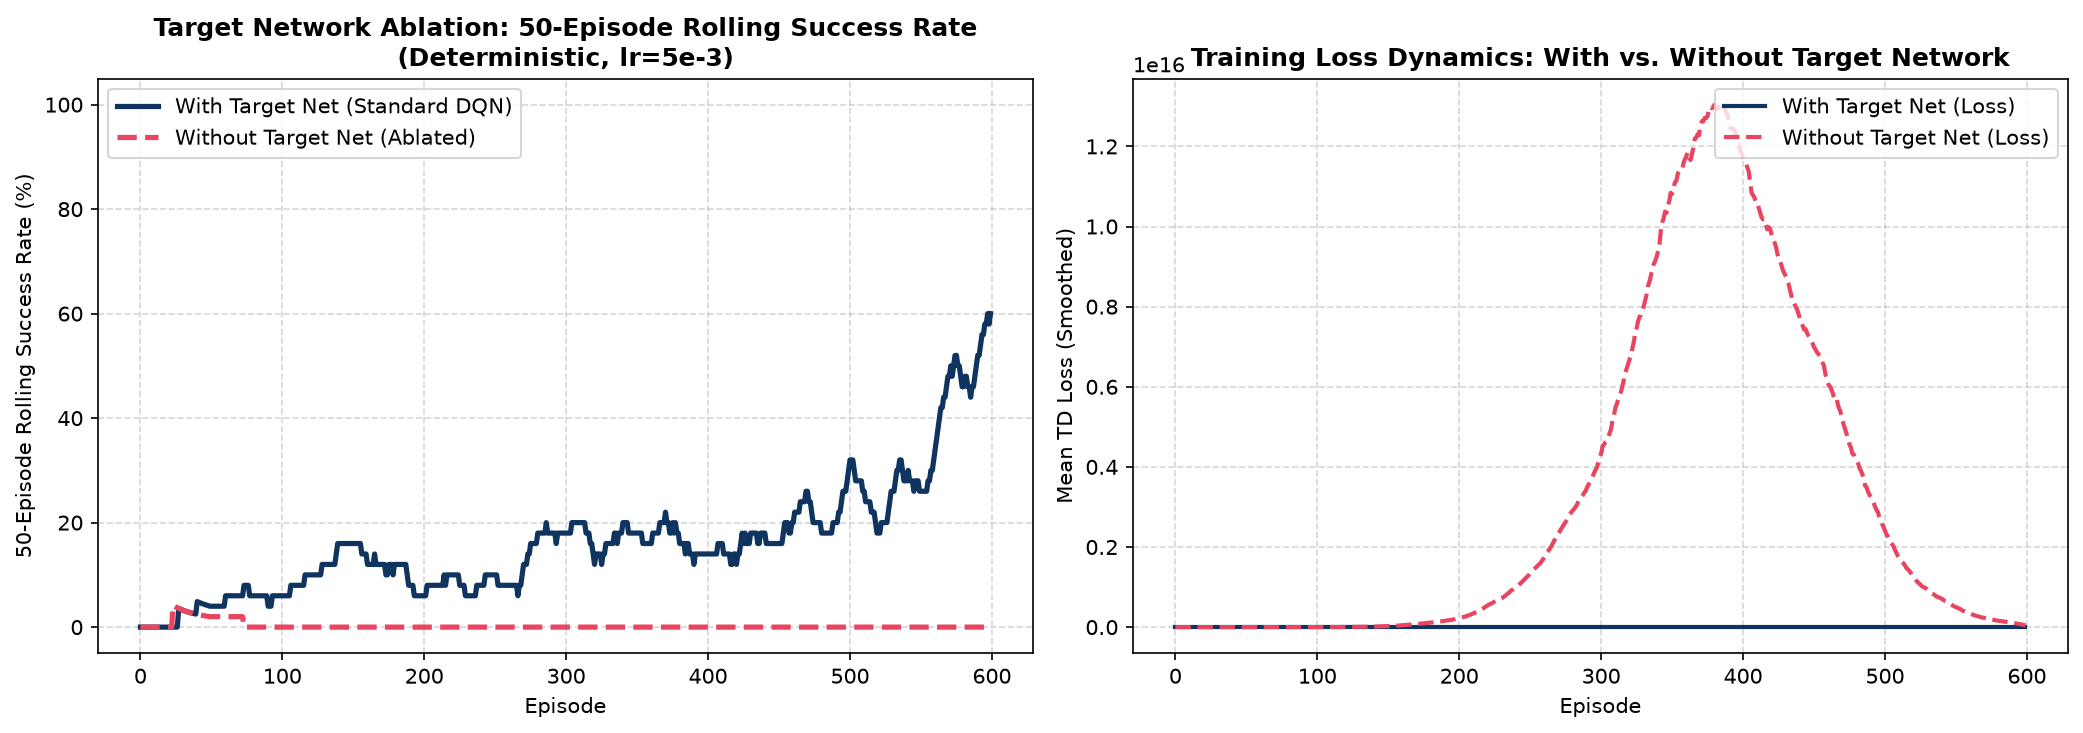

In [ ]:
# Plot Comparison of Rolling Success Rate and Loss Dynamics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Rolling Success Rate
ax1 = axes[0]
roll_with = [np.mean(r_with[max(0, i-49):i+1]) * 100 for i in range(len(r_with))]
roll_without = [np.mean(r_without[max(0, i-49):i+1]) * 100 for i in range(len(r_without))]
ax1.plot(roll_with, color="#0f3460", linewidth=2.5, label="With Target Net (Standard DQN)")
ax1.plot(roll_without, color="#e94560", linewidth=2.5, linestyle="--", label="Without Target Net (Ablated)")
ax1.set_xlabel("Episode")
ax1.set_ylabel("50-Episode Rolling Success Rate (%)")
ax1.set_title("50-Episode Rolling Success Rate: With vs. Without Target Net", fontweight="bold")
ax1.set_ylim(-5, 105)
ax1.legend(loc="upper left")
ax1.grid(True, linestyle="--", alpha=0.5)

# Loss Curves
ax2 = axes[1]
def smooth(y, box_pts=20):
    box = np.ones(box_pts)/box_pts
    return np.convolve(y, box, mode='same')

ax2.plot(smooth(loss_with), color="#0f3460", linewidth=2, label="With Target Net (Loss)")
ax2.plot(smooth(loss_without), color="#e94560", linewidth=2, linestyle="--", label="Without Target Net (Loss)")
ax2.set_xlabel("Episode")
ax2.set_ylabel("Mean TD Loss (Smoothed)")
ax2.set_title("Training Loss Dynamics: With vs. Without Target Network", fontweight="bold")
ax2.legend(loc="upper right")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


### Exercise 2: Target Network Stabilization Ablation

#### 1. Performance Comparison

* With `target_net`: The 50-episode rolling success rate climbs steadily toward $60.0\% - 90\%+$ even under the elevated learning rate of $5 \times 10^{-3}$.


* Without `target_net`: The rolling success rate stagnates near $0.0\%$ throughout the full 600 episodes. The agent undergoes catastrophic policy collapse and completely fails to converge on a viable route to the goal.



---

#### 2. Why does updating θ toward a target computed by the same θ on every step cause oscillations?
* Non-Stationary Target Problem: In standard supervised learning, the regression target is fixed. When bootstrapping directly from the online network weights $\theta$, updating $\theta$ simultaneously modifies the target $y_i = r_i + \gamma (1 - d_i) \max_{a'} Q_\theta(s_i', a')$ that the network is trying to predict. This creates a moving target problem where the network chases its own rapidly shifting outputs.


* Compounding Estimation Errors: At a relatively high learning rate ($\alpha = 0.005$), gradient updates cause substantial shifts in parameter space. An overestimation error in one state propagates backward into connected state-action pairs during successive updates. This feedback loop leads to severe oscillations in predicted values and triggers catastrophic forgetting of previously learned actions.


* Role of the Frozen Target Network: Decoupling target generation via parameter set $\theta^-$ keeps the regression objective stationary for $C = 20$ episodes. Freezing the Bellman target stabilizes the optimization landscape and allows standard gradient descent to minimize Bellman error effectively.